# Análisis preliminar — panel AMG 2020-2025

Continúa `01_eda.ipynb`. Usa `tesis_panel.db` y la población del Censo 2020.

In [1]:
import sqlite3, warnings
from pathlib import Path
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
pd.set_option("future.infer_string", False)

BASE = Path("..") / "contexto" / "mcdi tesis" / "db"
DB_PANEL = BASE / "tesis_panel.db"
DB_ORIG  = BASE / "tesis_desapariciones.db"
FIG, TAB = Path("figuras"), Path("tablas"); FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
SEED = 2026

POB = {"039": 1_385_629, "120": 1_476_491, "097": 727_750, "098": 687_127, "101": 569_913,
       "070": 232_852, "044": 67_969, "124": 64_806, "051": 30_855}  # Censo 2020
NOM = {"039": "Guadalajara", "120": "Zapopan", "097": "Tlajomulco", "098": "Tlaquepaque",
       "101": "Tonalá", "070": "El Salto", "044": "Ixtlahuacán", "124": "Zapotlanejo", "051": "Juanacatlán"}
CENTRALES = {"039", "120", "098", "101"}

con = sqlite3.connect(DB_PANEL)
panel = pd.read_sql("select cve_mun, anio, trimestre, casos from panel_municipio_trimestre", con)
panel["cve_mun"] = panel.cve_mun.astype(object)
panel["mun"] = panel.cve_mun.map(NOM)
panel["pob"] = panel.cve_mun.map(POB)
panel["tasa"] = panel.casos / panel.pob * 1e5
panel["periferico"] = (~panel.cve_mun.isin(CENTRALES)).astype(int)
panel["t"] = (panel.anio - 2020) * 4 + panel.trimestre - 1
panel["periodo"] = panel.anio.astype(str) + "T" + panel.trimestre.astype(str)
panel = panel.sort_values(["cve_mun", "t"]).reset_index(drop=True)
assert len(panel) == 216 and panel.casos.sum() == 18_142
print(panel.tasa.describe().round(2))

count    216.00
mean      14.07
std        6.67
min        0.00
25%       10.28
50%       13.57
75%       16.79
max       51.96
Name: tasa, dtype: float64


## 1. Cobertura CNB vs REPD por municipio

In [2]:
cnb = pd.read_sql("select cve_mun, count(*) colonias, sum(total) cnb_total, sum(desaparecidos) cnb_desap "
                  "from cnb_colonias_amg group by cve_mun", con)
repd = panel.groupby("cve_mun").casos.sum().rename("repd").reset_index()
comp = repd.merge(cnb, on="cve_mun", how="left").fillna(0)
comp["mun"] = comp.cve_mun.map(NOM)
comp["tipo"] = np.where(comp.cve_mun.isin(CENTRALES), "Central", "Periférico")
comp["cobertura"] = 100 * comp.cnb_total / comp.repd
comp = comp.sort_values("repd", ascending=False)
tipo_cov = comp.groupby("tipo")[["repd", "cnb_total"]].sum()
tipo_cov["cobertura"] = 100 * tipo_cov.cnb_total / tipo_cov.repd
print(comp[["mun", "tipo", "repd", "colonias", "cnb_total", "cobertura"]].round(1).to_string(index=False))
print(tipo_cov.round(1))

        mun       tipo  repd  colonias  cnb_total  cobertura
Guadalajara    Central  5320       484        298        5.6
    Zapopan    Central  4801       534        301        6.3
 Tlajomulco Periférico  2683        11          0        0.0
Tlaquepaque    Central  2216        63         43        1.9
     Tonalá    Central  1563       221        101        6.5
   El Salto Periférico  1047        30          0        0.0
Ixtlahuacán Periférico   275         4          1        0.4
Zapotlanejo Periférico   152        41          4        2.6
Juanacatlán Periférico    85        23          1        1.2
             repd  cnb_total  cobertura
tipo                                   
Central     13900        743        5.3
Periférico   4242          6        0.1


## 2. ENOE: desocupación por municipio-año
Cuarto trimestre, sin factor de expansión. Solo municipio-año con PEA >= 100.

In [3]:
eo = pd.read_sql("select mun, eda, clase1, clase2, ingocup, anios_esc, anio from enoe_sdemt", sqlite3.connect(DB_ORIG))
for c in ["mun", "eda", "clase1", "clase2", "ingocup", "anio"]:
    eo[c] = pd.to_numeric(eo[c], errors="coerce")
eo = eo.dropna(subset=["mun", "eda", "clase1"])
eo["cve_mun"] = eo.mun.astype(int).astype(str).str.zfill(3).astype(object)
eo = eo[eo.cve_mun.isin(POB) & eo.eda.between(15, 97)]
pea = eo[eo.clase1 == 1]
enoe = pea.groupby(["cve_mun", "anio"]).agg(n_pea=("clase1", "size"),
                                            desoc=("clase2", lambda s: (s == 2).mean()))
ocup = pea[(pea.clase2 == 1) & (pea.ingocup > 0)]
enoe["ingreso_med"] = ocup.groupby(["cve_mun", "anio"]).ingocup.median()
enoe = enoe.reset_index()
enoe_ok = enoe[enoe.n_pea >= 100].copy()
print(enoe_ok.assign(mun=enoe_ok.cve_mun.map(NOM)).pivot(index="mun", columns="anio", values="desoc").mul(100).round(1))
print("Municipios con ENOE suficiente:", sorted(enoe_ok.cve_mun.map(NOM).unique()))

anio         2020  2021  2022  2023  2024  2025
mun                                            
El Salto      7.2   0.8   NaN   NaN   4.8   3.5
Guadalajara   5.3   4.0   3.2   2.7   1.6   2.8
Tlajomulco    4.6   4.9   3.2   3.4   3.6   3.3
Tlaquepaque   5.9   3.6   3.3   2.4   2.9   2.6
Tonalá        5.0   2.5   3.3   3.3   2.5   2.3
Zapopan       2.8   3.4   2.1   1.7   1.8   3.2
Municipios con ENOE suficiente: ['El Salto', 'Guadalajara', 'Tlajomulco', 'Tlaquepaque', 'Tonalá', 'Zapopan']


## 3. Modelos de panel
3a. Varianza explicada por municipio y periodo

In [4]:
r2 = {}
for k, f in {"mun": "tasa ~ C(cve_mun)", "tiempo": "tasa ~ C(periodo)",
             "ambos": "tasa ~ C(cve_mun) + C(periodo)"}.items():
    r2[k] = smf.ols(f, panel).fit().rsquared
print({k: round(v, 3) for k, v in r2.items()})

{'mun': 0.17, 'tiempo': 0.22, 'ambos': 0.39}


3b. Tendencia centro vs periferia (EF municipio + trimestre del año)

In [5]:
f_tend = "tasa ~ C(cve_mun) + C(trimestre) + t + t:periferico"
m_tend = smf.ols(f_tend, panel).fit(cov_type="cluster", cov_kwds={"groups": panel.cve_mun.astype("category").cat.codes})
m_tend_hc = smf.ols(f_tend, panel).fit(cov_type="HC1")
for nm, m in [("cluster", m_tend), ("HC1", m_tend_hc)]:
    print(nm, m.params[["t", "t:periferico"]].round(3).to_dict(), m.bse[["t", "t:periferico"]].round(3).to_dict(),
          m.pvalues[["t", "t:periferico"]].round(3).to_dict())
print("Estacionalidad (vs T1):", m_tend.params.filter(like="C(trimestre)").round(2).to_dict(),
      m_tend.pvalues.filter(like="C(trimestre)").round(3).to_dict())
pend_c = 4 * m_tend.params["t"]; pend_p = 4 * (m_tend.params["t"] + m_tend.params["t:periferico"])
print("pendiente anual central", round(pend_c, 2), "periférico", round(pend_p, 2), "R2", round(m_tend.rsquared, 3))

cluster {'t': -0.227, 't:periferico': -0.258} {'t': 0.043, 't:periferico': 0.266} {'t': 0.0, 't:periferico': 0.331}
HC1 {'t': -0.227, 't:periferico': -0.258} {'t': 0.034, 't:periferico': 0.119} {'t': 0.0, 't:periferico': 0.03}
Estacionalidad (vs T1): {'C(trimestre)[T.2]': 0.08, 'C(trimestre)[T.3]': -0.01, 'C(trimestre)[T.4]': -2.05} {'C(trimestre)[T.2]': 0.924, 'C(trimestre)[T.3]': 0.989, 'C(trimestre)[T.4]': 0.026}
pendiente anual central -0.91 periférico -1.94 R2 0.367


3c. ENSU y ENOE a nivel municipio-año (agrupado vs EF)

In [6]:
anual = panel.groupby(["cve_mun", "anio"]).agg(casos=("casos", "sum"), pob=("pob", "first")).reset_index()
anual["tasa_anual"] = anual.casos / anual.pob * 1e5
ensu = pd.read_sql("select cve_mun, anio, pct_inseg_ciudad, pct_victima from ensu_indice_municipio", con)
ensu["cve_mun"] = ensu.cve_mun.astype(object)
an = anual.merge(ensu, on=["cve_mun", "anio"]).merge(enoe_ok[["cve_mun", "anio", "desoc"]], on=["cve_mun", "anio"], how="left")
an["inseg"] = 100 * an.pct_inseg_ciudad
an["desoc_pp"] = 100 * an.desoc
print(len(an), "municipio-año;", an.desoc.notna().sum(), "con ENOE")

mods = {
    "agrupado":      smf.ols("tasa_anual ~ inseg", an).fit(cov_type="HC1"),
    "ef":            smf.ols("tasa_anual ~ inseg + C(cve_mun) + C(anio)", an).fit(cov_type="HC1"),
    "ef_desoc":      smf.ols("tasa_anual ~ inseg + desoc_pp + C(cve_mun) + C(anio)", an.dropna(subset=["desoc_pp"])).fit(cov_type="HC1"),
}
for k, m in mods.items():
    cols = [c for c in ["inseg", "desoc_pp"] if c in m.params]
    print(k, "n", int(m.nobs), {c: (round(m.params[c], 2), round(m.bse[c], 2), round(m.pvalues[c], 3)) for c in cols},
          "R2", round(m.rsquared, 3))
# correlación entre y dentro de municipio
an["tasa_w"] = an.tasa_anual - an.groupby("cve_mun").tasa_anual.transform("mean")
an["inseg_w"] = an.inseg - an.groupby("cve_mun").inseg.transform("mean")
rho_between = an.groupby("cve_mun")[["tasa_anual", "inseg"]].mean().corr(method="spearman").iloc[0, 1]
rho_within = an[["tasa_w", "inseg_w"]].corr(method="spearman").iloc[0, 1]
print("Spearman entre municipios (medias, n=5):", round(rho_between, 2), " dentro de municipio (n=20):", round(rho_within, 2))

20 municipio-año; 20 con ENOE
agrupado n 20 {'inseg': (0.45, 0.21, 0.036)} R2 0.176
ef n 20 {'inseg': (-0.17, 0.12, 0.156)} R2 0.948
ef_desoc n 20 {'inseg': (-0.16, 0.1, 0.112), 'desoc_pp': (-2.18, 1.31, 0.097)} R2 0.956
Spearman entre municipios (medias, n=5): 0.7  dentro de municipio (n=20): 0.18


## 4. Comparación predictiva con validación temporal
Ventana creciente por año (2022-2025), pronóstico a un trimestre.

In [7]:
d = panel.copy()
g = d.groupby("cve_mun").tasa
d["lag1"], d["lag2"], d["lag4"] = g.shift(1), g.shift(2), g.shift(4)
d["ma4"] = g.transform(lambda s: s.shift(1).rolling(4).mean())
d["log_pob"] = np.log(d.pob)
d = d.dropna(subset=["lag4", "ma4"]).reset_index(drop=True)
MUN_D = pd.get_dummies(d.cve_mun, prefix="m", drop_first=True).astype(float)
TRI_D = pd.get_dummies(d.trimestre, prefix="q", drop_first=True).astype(float)
X_tree = pd.concat([d[["lag1", "lag2", "lag4", "ma4", "log_pob", "periferico", "trimestre", "t"]],
                    pd.get_dummies(d.cve_mun, prefix="m").astype(float)], axis=1)
X_fe_static = pd.concat([MUN_D, TRI_D, d[["t"]]], axis=1)
X_fe_dyn = pd.concat([MUN_D, TRI_D, d[["lag1", "lag4"]]], axis=1)
y = d.tasa.values

def modelos():
    return {
        "Panel EF estático": (LinearRegression(), X_fe_static),
        "Panel EF dinámico": (LinearRegression(), X_fe_dyn),
        "Random Forest": (RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEED, n_jobs=-1), X_tree),
        "XGBoost": (XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                                 colsample_bytree=0.8, random_state=SEED), X_tree),
    }

filas, preds = [], []
for anio_test in [2022, 2023, 2024, 2025]:
    tr, te = (d.anio < anio_test).values, (d.anio == anio_test).values
    filas.append(dict(modelo="Ingenuo (t-4)", anio=anio_test,
                      rmse=mean_squared_error(y[te], d.lag4[te]) ** .5, mae=mean_absolute_error(y[te], d.lag4[te])))
    for nm, (mdl, X) in modelos().items():
        mdl.fit(X[tr], y[tr]); p = mdl.predict(X[te])
        filas.append(dict(modelo=nm, anio=anio_test, rmse=mean_squared_error(y[te], p) ** .5, mae=mean_absolute_error(y[te], p)))
        preds.append(pd.DataFrame({"modelo": nm, "anio": anio_test, "cve_mun": d.cve_mun[te], "t": d.t[te], "y": y[te], "p": p}))
cv = pd.DataFrame(filas)
preds = pd.concat(preds)
orden = ["Ingenuo (t-4)", "Panel EF estático", "Panel EF dinámico", "Random Forest", "XGBoost"]
res_cv = cv.groupby("modelo")[["rmse", "mae"]].mean().loc[orden]
print(cv.pivot(index="modelo", columns="anio", values="rmse").loc[orden].round(2))
print(res_cv.round(2))

anio               2022  2023  2024  2025
modelo                                   
Ingenuo (t-4)      6.05  6.91  7.06  5.64
Panel EF estático  5.20  5.79  4.13  4.65
Panel EF dinámico  5.86  5.71  4.58  4.11
Random Forest      4.24  5.67  4.35  4.42
XGBoost            4.82  5.06  4.74  4.94
                   rmse   mae
modelo                       
Ingenuo (t-4)      6.42  4.70
Panel EF estático  4.94  3.54
Panel EF dinámico  5.07  3.74
Random Forest      4.67  3.43
XGBoost            4.89  3.57


Prueba final 2024-2025 e importancia por permutación

In [8]:
tr, te = (d.anio <= 2023).values, (d.anio >= 2024).values
hold, fitted = [], {}
for nm, (mdl, X) in modelos().items():
    mdl.fit(X[tr], y[tr]); p = mdl.predict(X[te]); fitted[nm] = (mdl, X)
    per = d.periferico[te].values == 1
    hold.append(dict(modelo=nm, rmse=mean_squared_error(y[te], p) ** .5, mae=mean_absolute_error(y[te], p),
                     r2=r2_score(y[te], p), rmse_c=mean_squared_error(y[te][~per], p[~per]) ** .5,
                     rmse_p=mean_squared_error(y[te][per], p[per]) ** .5))
p0 = d.lag4[te].values; per = d.periferico[te].values == 1
hold.insert(0, dict(modelo="Ingenuo (t-4)", rmse=mean_squared_error(y[te], p0) ** .5, mae=mean_absolute_error(y[te], p0),
                    r2=r2_score(y[te], p0), rmse_c=mean_squared_error(y[te][~per], p0[~per]) ** .5,
                    rmse_p=mean_squared_error(y[te][per], p0[per]) ** .5))
hold = pd.DataFrame(hold).set_index("modelo")
print(hold.round(2))

# importancia por permutación
imp = {}
for nm in ["XGBoost", "Random Forest"]:
    mdl, X = fitted[nm]
    r = permutation_importance(mdl, X[te], y[te], n_repeats=30, random_state=SEED, scoring="neg_root_mean_squared_error")
    s = pd.Series(r.importances_mean, index=X.columns)
    mun_cols = [c for c in X.columns if c.startswith("m_")]
    s = pd.concat([s.drop(mun_cols), pd.Series({"municipio (9 indicadores)": s[mun_cols].sum()})])
    imp[nm] = s.sort_values(ascending=False)
print(pd.DataFrame(imp).round(3))

                   rmse   mae    r2  rmse_c  rmse_p
modelo                                             
Ingenuo (t-4)      6.39  4.54 -0.74    2.87    8.18
Panel EF estático  4.42  3.12  0.17    2.10    5.63
Panel EF dinámico  4.58  3.64  0.11    3.13    5.47
Random Forest      4.51  3.46  0.13    2.53    5.62
XGBoost            4.99  3.79 -0.06    2.77    6.22


                           XGBoost  Random Forest
lag1                         0.352          0.296
lag2                        -0.195         -0.155
lag4                         0.025          0.101
log_pob                      0.429          0.196
ma4                         -0.447          0.194
municipio (9 indicadores)    0.175          0.081
periferico                   0.002          0.007
t                            0.000          0.000
trimestre                    0.220          0.107


## 5. Figuras

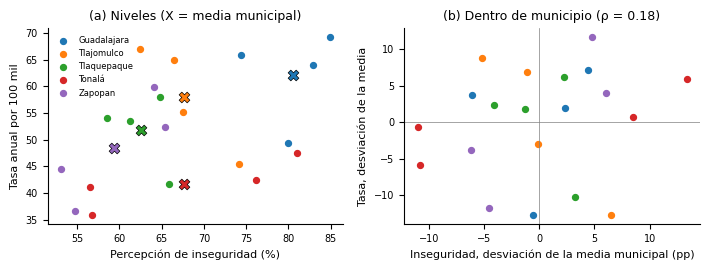

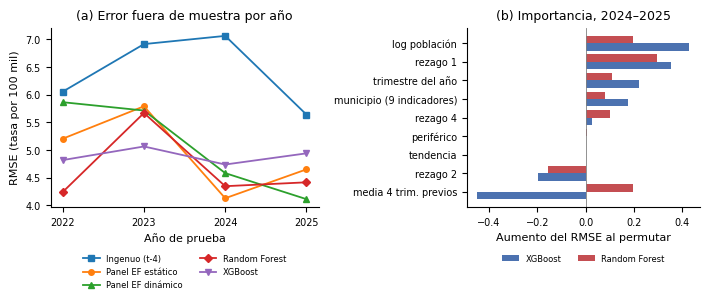

In [9]:
# Figura: entre y dentro de municipio
cols = {"Guadalajara": "#1f77b4", "Tlajomulco": "#ff7f0e", "Tlaquepaque": "#2ca02c", "Tonalá": "#d62728", "Zapopan": "#9467bd"}
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.8))
for cve, gg in an.groupby("cve_mun"):
    c = cols[NOM[cve]]
    ax[0].scatter(gg.inseg, gg.tasa_anual, color=c, s=18, label=NOM[cve])
    ax[1].scatter(gg.inseg_w, gg.tasa_w, color=c, s=18)
    ax[0].scatter(gg.inseg.mean(), gg.tasa_anual.mean(), color=c, marker="X", s=60, edgecolor="k", lw=.5)
for a in ax: a.spines[["top", "right"]].set_visible(False); a.tick_params(labelsize=7)
ax[0].set_xlabel("Percepción de inseguridad (%)", fontsize=8); ax[0].set_ylabel("Tasa anual por 100 mil", fontsize=8)
ax[0].set_title(f"(a) Niveles (X = media municipal)", fontsize=9)
ax[1].axhline(0, color="grey", lw=.5); ax[1].axvline(0, color="grey", lw=.5)
ax[1].set_xlabel("Inseguridad, desviación de la media municipal (pp)", fontsize=8)
ax[1].set_ylabel("Tasa, desviación de la media", fontsize=8)
ax[1].set_title(f"(b) Dentro de municipio (ρ = {rho_within:.2f})", fontsize=9)
ax[0].legend(fontsize=6, frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "fig6_entre_dentro.pdf"); plt.show()

# Figura: validación e importancia
fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.3), gridspec_kw={"width_ratios": [1.15, 1]})
piv = cv.pivot(index="anio", columns="modelo", values="rmse")[orden]
mk = dict(zip(orden, ["s", "o", "^", "D", "v"]))
for m in orden: ax[0].plot(piv.index, piv[m], marker=mk[m], ms=4, lw=1.3, label=m)
ax[0].set_xticks(piv.index); ax[0].set_ylabel("RMSE (tasa por 100 mil)", fontsize=8); ax[0].set_xlabel("Año de prueba", fontsize=8)
ax[0].set_title("(a) Error fuera de muestra por año", fontsize=9)
ax[0].legend(fontsize=6, frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.22))
nombres = {"ma4": "media 4 trim. previos", "lag1": "rezago 1", "lag2": "rezago 2", "lag4": "rezago 4",
           "log_pob": "log población", "periferico": "periférico", "trimestre": "trimestre del año", "t": "tendencia"}
impdf = pd.DataFrame(imp).sort_values("XGBoost")
yy = np.arange(len(impdf))
ax[1].barh(yy - .2, impdf["XGBoost"], height=.4, color="#4C72B0", label="XGBoost")
ax[1].barh(yy + .2, impdf["Random Forest"], height=.4, color="#C44E52", label="Random Forest")
ax[1].set_yticks(yy); ax[1].set_yticklabels([nombres.get(i, i) for i in impdf.index])
ax[1].axvline(0, color="grey", lw=.6)
ax[1].legend(fontsize=6, frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax[1].set_xlabel("Aumento del RMSE al permutar", fontsize=8); ax[1].set_title("(b) Importancia, 2024–2025", fontsize=9)
for a in ax: a.spines[["top", "right"]].set_visible(False); a.tick_params(labelsize=7)
fig.tight_layout(); fig.savefig(FIG / "fig7_validacion_importancia.pdf"); plt.show()

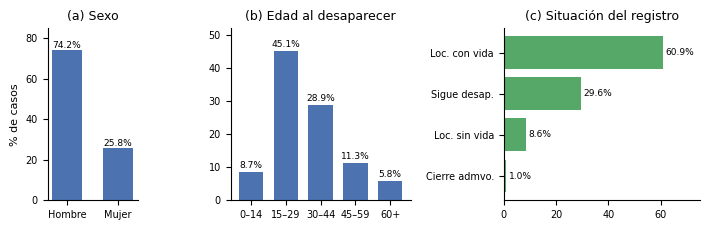

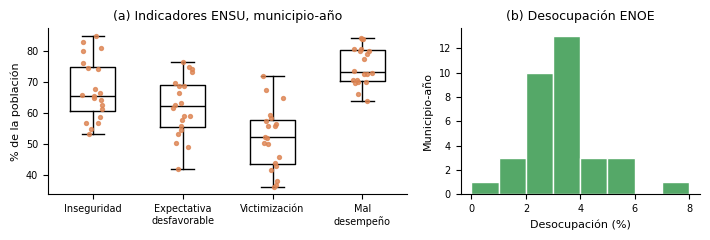

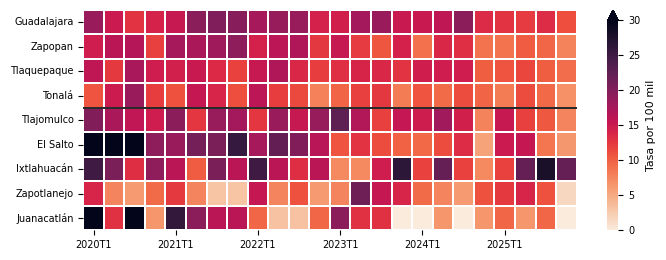

celdas por encima de 30 : 5


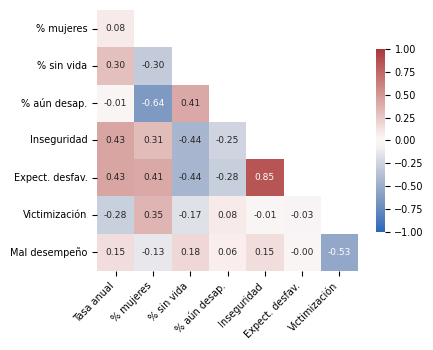

n = 20 | rho tasa-inseg = 0.43
         var_obs  var_pois      pob  share          mun
cve_mun                                                
039         7.51      1.15  1385629   0.15  Guadalajara
044        38.58     24.80    67969   0.64  Ixtlahuacán
051        94.97     37.20    30855   0.39  Juanacatlán
070       145.64      8.05   232852   0.06     El Salto
097        13.97      2.11   727750   0.15   Tlajomulco
098         4.52      1.96   687127   0.43  Tlaquepaque
101         7.67      2.01   569913   0.26       Tonalá
120        11.42      0.92  1476491   0.08      Zapopan
124        21.26     15.08    64806   0.71  Zapotlanejo


In [10]:
import seaborn as sns
casos = pd.read_sql("select sexo, rango_de_edad, estatus, condicion_localizacion from repd_amg_casos", con)
def grupo_edad(r):
    if not isinstance(r, str) or r.strip() == "": return "Sin dato"
    ini = int(r.replace("+", "").split("-")[0])
    for lim, et in [(15, "0–14"), (30, "15–29"), (45, "30–44"), (60, "45–59")]:
        if ini < lim: return et
    return "60+"
casos["edad"] = casos.rango_de_edad.map(grupo_edad)
casos["situacion"] = np.select([casos.estatus.eq("PERSONA DESAPARECIDA"), casos.condicion_localizacion.eq("CON VIDA"),
                                casos.condicion_localizacion.eq("SIN VIDA")],
                               ["Sigue desaparecida", "Localizada con vida", "Localizada sin vida"], "Cierre administrativo")

# Figura: perfil de los casos
fig, ax = plt.subplots(1, 3, figsize=(7.2, 2.4), gridspec_kw={"width_ratios": [0.55, 1.1, 1.2]})
sx = casos.sexo.str.title().value_counts(normalize=True).mul(100)
ax[0].bar(sx.index, sx.values, color="#4C72B0", width=.6); ax[0].set_ylim(0, 85)
ed = casos.edad.value_counts(normalize=True).mul(100).reindex(["0–14", "15–29", "30–44", "45–59", "60+"])
ax[1].bar(ed.index, ed.values, color="#4C72B0", width=.7); ax[1].set_ylim(0, 52)
st = casos.situacion.value_counts(normalize=True).mul(100).sort_values()
corto = {"Cierre administrativo": "Cierre admvo.", "Localizada sin vida": "Loc. sin vida",
         "Sigue desaparecida": "Sigue desap.", "Localizada con vida": "Loc. con vida"}
ax[2].barh(st.index.map(corto), st.values, color="#55A868")
for a, ser in [(ax[0], sx), (ax[1], ed)]:
    for x, v in enumerate(ser.values): a.text(x, v + 1.2, f"{v:.1f}%", ha="center", fontsize=6.5)
for y, v in enumerate(st.values): ax[2].text(v + 1, y, f"{v:.1f}%", va="center", fontsize=6.5)
ax[2].set_xlim(0, 75)
ax[0].set_ylabel("% de casos", fontsize=8)
for a, t in zip(ax, ["(a) Sexo", "(b) Edad al desaparecer", "(c) Situación del registro"]):
    a.set_title(t, fontsize=9); a.spines[["top", "right"]].set_visible(False); a.tick_params(labelsize=7)
fig.tight_layout(); fig.savefig(FIG / "fig_casos.pdf"); plt.show()

# Figura: covariables
ensu_l = pd.read_sql("select pct_inseg_ciudad, pct_espera_mal, pct_victima, pct_desempeno_malo from ensu_indice_municipio", con).mul(100)
ensu_l.columns = ["Inseguridad", "Expectativa\ndesfavorable", "Victimización", "Mal\ndesempeño"]
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].boxplot(ensu_l.values, widths=.5, medianprops=dict(color="k"))
for j in range(ensu_l.shape[1]):
    ax[0].scatter(np.full(len(ensu_l), j + 1) + np.random.default_rng(j).uniform(-.12, .12, len(ensu_l)),
                  ensu_l.iloc[:, j], s=8, color="#DD8452", alpha=.8, zorder=3)
ax[0].set_xticks(range(1, 5)); ax[0].set_xticklabels(ensu_l.columns, fontsize=7)
ax[0].set_ylabel("% de la población", fontsize=8); ax[0].set_title("(a) Indicadores ENSU, municipio-año", fontsize=9)
ax[1].hist(100 * enoe_ok.desoc, bins=np.arange(0, 8.5, 1), color="#55A868", edgecolor="white")
ax[1].set_xlabel("Desocupación (%)", fontsize=8); ax[1].set_ylabel("Municipio-año", fontsize=8)
ax[1].set_title("(b) Desocupación ENOE", fontsize=9)
for a in ax: a.spines[["top", "right"]].set_visible(False); a.tick_params(labelsize=7)
fig.tight_layout(); fig.savefig(FIG / "fig_covariables.pdf"); plt.show()

# Figura: mapa de calor
orden_mun = ["Guadalajara", "Zapopan", "Tlaquepaque", "Tonalá", "Tlajomulco", "El Salto", "Ixtlahuacán", "Zapotlanejo", "Juanacatlán"]
hm = panel.pivot(index="mun", columns="periodo", values="tasa").loc[orden_mun]
VMAX = 30
fig, ax = plt.subplots(figsize=(7.2, 2.7))
sns.heatmap(hm, cmap="rocket_r", vmin=0, vmax=VMAX, linewidths=.3, linecolor="white", ax=ax,
            cbar_kws={"label": "Tasa por 100 mil", "extend": "max"})
ax.axhline(4, color="k", lw=1.2)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_xticks(np.arange(0, 24, 4) + .5); ax.set_xticklabels([f"{y}T1" for y in range(2020, 2026)], rotation=0)
ax.tick_params(labelsize=7); ax.figure.axes[-1].tick_params(labelsize=7); ax.figure.axes[-1].yaxis.label.set_size(8)
fig.tight_layout(); fig.savefig(FIG / "fig_heatmap.pdf"); plt.show()
n_sat = int((panel.tasa > VMAX).sum()); print("celdas por encima de", VMAX, ":", n_sat)

# Figura: correlaciones
pm = pd.read_sql("select * from panel_municipio_trimestre", con)
pm["cve_mun"] = pm.cve_mun.astype(object)
ma = (pm.groupby(["cve_mun", "anio"]).agg(casos=("casos", "sum"), pct_mujeres=("pct_mujeres", "mean"),
      pct_sin_vida=("pct_sin_vida", "mean"), pct_sigue_desap=("pct_sigue_desap", "mean"),
      pct_inseg_ciudad=("pct_inseg_ciudad", "first"), pct_espera_mal=("pct_espera_mal", "first"),
      pct_victima=("pct_victima", "first"), pct_desempeno_malo=("pct_desempeno_malo", "first")).reset_index())
ma["tasa_anual"] = ma.casos / ma.cve_mun.map(POB) * 1e5
ma = ma.dropna(subset=["pct_inseg_ciudad"])
CV = {"tasa_anual": "Tasa anual", "pct_mujeres": "% mujeres", "pct_sin_vida": "% sin vida", "pct_sigue_desap": "% aún desap.",
      "pct_inseg_ciudad": "Inseguridad", "pct_espera_mal": "Expect. desfav.", "pct_victima": "Victimización",
      "pct_desempeno_malo": "Mal desempeño"}
corr = ma[list(CV)].corr(method="spearman").rename(index=CV, columns=CV)
fig, ax = plt.subplots(figsize=(4.6, 3.6))
cplot = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(cplot, dtype=bool), 1)
sns.heatmap(cplot, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax, square=True,
            annot_kws={"size": 6.5}, cbar_kws={"shrink": .7})
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right"); ax.tick_params(labelsize=7)
ax.figure.axes[-1].tick_params(labelsize=7)
fig.tight_layout(); fig.savefig(FIG / "fig_correlaciones.pdf"); plt.show()
print("n =", len(ma), "| rho tasa-inseg =", round(corr.loc["Tasa anual", "Inseguridad"], 2))

# ruido Poisson vs varianza observada
panel["lam"] = panel.groupby("cve_mun").casos.transform("mean")
panel["var_pois"] = panel.lam / panel.pob ** 2 * 1e10
ruido = panel.groupby("cve_mun").agg(var_obs=("tasa", "var"), var_pois=("var_pois", "mean"), pob=("pob", "first"))
ruido["share"] = ruido.var_pois / ruido.var_obs
peq = ruido[ruido.pob < 100_000]
print(ruido.assign(mun=ruido.index.map(NOM)).round(2))

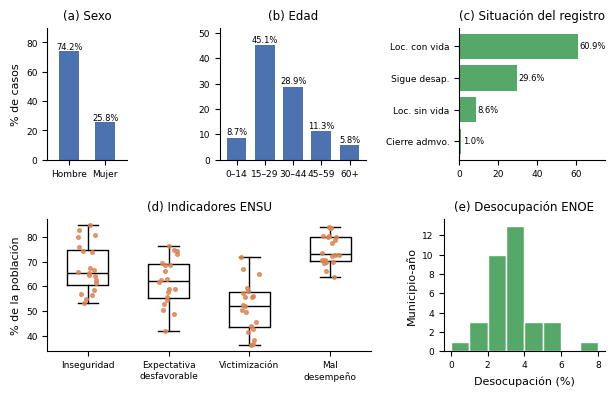

In [11]:
# Figura: univariantes (casos y covariables)
fig = plt.figure(figsize=(7.2, 4.2))
gs = fig.add_gridspec(2, 1, hspace=.45)
top = gs[0].subgridspec(1, 3, width_ratios=[1.2, 2.2, 2.2], wspace=.75)
bot = gs[1].subgridspec(1, 2, width_ratios=[2, 1], wspace=.3)
a1, a2, a3 = (fig.add_subplot(top[k]) for k in range(3))
b1, b2 = fig.add_subplot(bot[0]), fig.add_subplot(bot[1])
a1.bar(sx.index, sx.values, color="#4C72B0", width=.55); a1.set_ylim(0, 90); a1.set_xlim(-.6, 1.6); a1.set_ylabel("% de casos", fontsize=8)
a2.bar(ed.index, ed.values, color="#4C72B0", width=.7); a2.set_ylim(0, 52)
for a, ser in [(a1, sx), (a2, ed)]:
    for x, v in enumerate(ser.values): a.text(x, v + 1.2, f"{v:.1f}%", ha="center", fontsize=6)
a3.barh(st.index.map(corto), st.values, color="#55A868"); a3.set_xlim(0, 75)
for y, v in enumerate(st.values): a3.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=6)
b1.boxplot(ensu_l.values, widths=.5, medianprops=dict(color="k"))
for j in range(ensu_l.shape[1]):
    b1.scatter(np.full(len(ensu_l), j + 1) + np.random.default_rng(j).uniform(-.12, .12, len(ensu_l)),
               ensu_l.iloc[:, j], s=7, color="#DD8452", alpha=.8, zorder=3)
b1.set_xticks(range(1, 5)); b1.set_xticklabels(ensu_l.columns, fontsize=7); b1.set_ylabel("% de la población", fontsize=8)
b2.hist(100 * enoe_ok.desoc, bins=np.arange(0, 8.5, 1), color="#55A868", edgecolor="white")
b2.set_xlabel("Desocupación (%)", fontsize=8); b2.set_ylabel("Municipio-año", fontsize=8)
for a, t in zip([a1, a2, a3, b1, b2], ["(a) Sexo", "(b) Edad", "(c) Situación del registro",
                                      "(d) Indicadores ENSU", "(e) Desocupación ENOE"]):
    a.set_title(t, fontsize=8.5); a.spines[["top", "right"]].set_visible(False); a.tick_params(labelsize=6.5)
fig.savefig(FIG / "fig_univariantes.pdf", bbox_inches="tight"); plt.show()

## 6. Exportación a LaTeX

In [12]:
def f2(x): return f"{x:,.2f}".replace("-", "\u2212")
def f1(x): return f"{x:,.1f}"
def f0(x): return f"{x:,.0f}"
def stars(p): return "\\textsuperscript{***}" if p < .01 else "\\textsuperscript{**}" if p < .05 else "\\textsuperscript{*}" if p < .1 else ""

# Tabla: cobertura CNB vs REPD
with open(TAB / "tabla_cnb_repd.tex", "w") as fh:
    for _, r in comp.iterrows():
        fh.write(f"{r.mun} & {r.tipo} & {f0(r.repd)} & {f0(r.colonias)} & {f0(r.cnb_total)} & {f1(r.cobertura)} \\\\\n")
    fh.write("\\midrule\n")
    for tp, r in tipo_cov.iterrows():
        fh.write(f"Total {tp.lower()} & & {f0(r.repd)} & & {f0(r.cnb_total)} & {f1(r.cobertura)} \\\\\n")

# Tabla: modelos de panel (3b y 3c)
def cel(m, v): return f"{f2(m.params[v])}{stars(m.pvalues[v])}" if v in m.params else ""
def se(m, v): return f"({f2(m.bse[v])})" if v in m.params else ""
with open(TAB / "tabla_panel.tex", "w") as fh:
    fh.write(f"Tendencia trimestral ($t$) & {f2(m_tend.params['t'])}{stars(m_tend.pvalues['t'])} & & & \\\\\n")
    fh.write(f" & ({f2(m_tend.bse['t'])}) & & & \\\\\n")
    fh.write(f"$t \\times$ periférico & {f2(m_tend.params['t:periferico'])}{stars(m_tend.pvalues['t:periferico'])} & & & \\\\\n")
    fh.write(f" & ({f2(m_tend.bse['t:periferico'])}) & & & \\\\\n")
    fh.write(f"Percepción de inseguridad (pp) & & {cel(mods['agrupado'],'inseg')} & {cel(mods['ef'],'inseg')} & {cel(mods['ef_desoc'],'inseg')} \\\\\n")
    fh.write(f" & & {se(mods['agrupado'],'inseg')} & {se(mods['ef'],'inseg')} & {se(mods['ef_desoc'],'inseg')} \\\\\n")
    fh.write(f"Desocupación ENOE (pp) & & & & {cel(mods['ef_desoc'],'desoc_pp')} \\\\\n")
    fh.write(f" & & & & {se(mods['ef_desoc'],'desoc_pp')} \\\\\n")
    fh.write("\\midrule\n")
    fh.write("Efectos fijos de municipio & Sí & No & Sí & Sí \\\\\n")
    fh.write("Efectos fijos de tiempo & Trimestre del año & No & Año & Año \\\\\n")
    fh.write(f"Observaciones & {int(m_tend.nobs)} & {int(mods['agrupado'].nobs)} & {int(mods['ef'].nobs)} & {int(mods['ef_desoc'].nobs)} \\\\\n")
    fh.write(f"$R^2$ & {f2(m_tend.rsquared)} & {f2(mods['agrupado'].rsquared)} & {f2(mods['ef'].rsquared)} & {f2(mods['ef_desoc'].rsquared)} \\\\\n")

# Tabla: comparación predictiva
with open(TAB / "tabla_predictiva.tex", "w") as fh:
    for m in orden:
        h = hold.loc[m]; c = res_cv.loc[m]
        fh.write(f"{m} & {f2(c.rmse)} & {f2(c.mae)} & {f2(h.rmse)} & {f2(h.mae)} & {f2(h.r2)} & {f2(h.rmse_c)} & {f2(h.rmse_p)} \\\\\n")

# Tabla ENOE
tab_enoe = enoe_ok.assign(mun=enoe_ok.cve_mun.map(NOM)).pivot(index="mun", columns="anio", values="desoc").mul(100)
tab_enoe = tab_enoe.loc[tab_enoe.mean(axis=1).sort_values(ascending=False).index]
with open(TAB / "tabla_enoe.tex", "w") as fh:
    for mun, r in tab_enoe.iterrows():
        fh.write(mun + " & " + " & ".join("--" if pd.isna(v) else f1(v) for v in r.values) + " \\\\\n")

best = res_cv.rmse.idxmin()
xgb_top = imp["XGBoost"].index[0]
M = {
    "CNBTotal": f0(comp.cnb_total.sum()), "CNBCobertura": f1(100 * comp.cnb_total.sum() / comp.repd.sum()),
    "CNBCobCentral": f1(tipo_cov.loc["Central", "cobertura"]), "CNBCobPeriferico": f1(tipo_cov.loc["Periférico", "cobertura"]),
    "RDosMun": f2(r2["mun"]), "RDosTiempo": f2(r2["tiempo"]), "RDosAmbos": f2(r2["ambos"]),
    "TendCentral": f2(m_tend.params["t"]), "TendInter": f2(m_tend.params["t:periferico"]),
    "TendInterP": f"{m_tend.pvalues['t:periferico']:.3f}", "TendCentralP": f"{m_tend.pvalues['t']:.3f}",
    "PendAnualCentral": f2(pend_c), "PendAnualPeriferico": f2(pend_p),
    "EstacCuarto": f2(m_tend.params["C(trimestre)[T.4]"]), "EstacCuartoP": f"{m_tend.pvalues['C(trimestre)[T.4]']:.3f}",
    "InsegAgr": f2(mods["agrupado"].params["inseg"]), "InsegAgrP": f"{mods['agrupado'].pvalues['inseg']:.3f}",
    "InsegEF": f2(mods["ef"].params["inseg"]), "InsegEFP": f"{mods['ef'].pvalues['inseg']:.3f}",
    "DesocEF": f2(mods["ef_desoc"].params["desoc_pp"]), "DesocEFP": f"{mods['ef_desoc'].pvalues['desoc_pp']:.3f}",
    "NENOE": str(int(mods["ef_desoc"].nobs)), "NMunENOE": str(enoe_ok.cve_mun.nunique()),
    "RhoEntre": f2(rho_between), "RhoDentro": f2(rho_within),
    "MejorModelo": best,
    "RuidoPeqMin": f"{100*peq.share.min():.0f}", "RuidoPeqMax": f"{100*peq.share.max():.0f}",
    "RuidoGrandeMax": f"{100*ruido[ruido.pob >= 500_000].share.max():.0f}", "HeatSat": str(n_sat),
    "NENOEMunAnio": str(len(enoe_ok)), "DesocMed": f1(100 * enoe_ok.desoc.median()),
    "DesocMin": f1(100 * enoe_ok.desoc.min()), "DesocMax": f1(100 * enoe_ok.desoc.max()),
    **{f"RMSECV{k}": f2(res_cv.loc[m, "rmse"]) for k, m in zip(["Ing", "EFE", "EFD", "RF", "XGB"], orden)},
    **{f"RMSEH{k}": f2(hold.loc[m, "rmse"]) for k, m in zip(["Ing", "EFE", "EFD", "RF", "XGB"], orden)},
    **{f"RDosH{k}": f2(hold.loc[m, "r2"]) for k, m in zip(["Ing", "EFE", "EFD", "RF", "XGB"], orden)},
    **{f"RMSEP{k}": f2(hold.loc[m, "rmse_p"]) for k, m in zip(["Ing", "EFE", "EFD", "RF", "XGB"], orden)},
    **{f"RMSEC{k}": f2(hold.loc[m, "rmse_c"]) for k, m in zip(["Ing", "EFE", "EFD", "RF", "XGB"], orden)},
}
with open("resultados_modelos.tex", "w") as fh:
    fh.write("% Generado automáticamente por analisis_preliminar.ipynb. No editar a mano.\n")
    for k, v in M.items(): fh.write(f"\\newcommand{{\\M{k}}}{{{v}}}\n")
for k, v in M.items(): print(k, v)

CNBTotal 749
CNBCobertura 4.1
CNBCobCentral 5.3
CNBCobPeriferico 0.1
RDosMun 0.17
RDosTiempo 0.22
RDosAmbos 0.39
TendCentral −0.23
TendInter −0.26
TendInterP 0.331
TendCentralP 0.000
PendAnualCentral −0.91
PendAnualPeriferico −1.94
EstacCuarto −2.05
EstacCuartoP 0.026
InsegAgr 0.45
InsegAgrP 0.036
InsegEF −0.17
InsegEFP 0.156
DesocEF −2.18
DesocEFP 0.097
NENOE 20
NMunENOE 6
RhoEntre 0.70
RhoDentro 0.18
MejorModelo Random Forest
RuidoPeqMin 39
RuidoPeqMax 71
RuidoGrandeMax 43
HeatSat 5
NENOEMunAnio 34
DesocMed 3.2
DesocMin 0.8
DesocMax 7.2
RMSECVIng 6.42
RMSECVEFE 4.94
RMSECVEFD 5.07
RMSECVRF 4.67
RMSECVXGB 4.89
RMSEHIng 6.39
RMSEHEFE 4.42
RMSEHEFD 4.58
RMSEHRF 4.51
RMSEHXGB 4.99
RDosHIng −0.74
RDosHEFE 0.17
RDosHEFD 0.11
RDosHRF 0.13
RDosHXGB −0.06
RMSEPIng 8.18
RMSEPEFE 5.63
RMSEPEFD 5.47
RMSEPRF 5.62
RMSEPXGB 6.22
RMSECIng 2.87
RMSECEFE 2.10
RMSECEFD 3.13
RMSECRF 2.53
RMSECXGB 2.77
